In [28]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})


def shape(a, b, c, d, x):
    """Trapezoid fuzzy set: rises from a to b, stays at 1 until c, falls to d."""
    up = (x >= a).astype(float) if b == a else (x - a) / (b - a)
    down = (x <= d).astype(float) if d == c else (d - x) / (d - c)
    return np.clip(np.minimum(up, down), 0, 1)

## Money range membership function

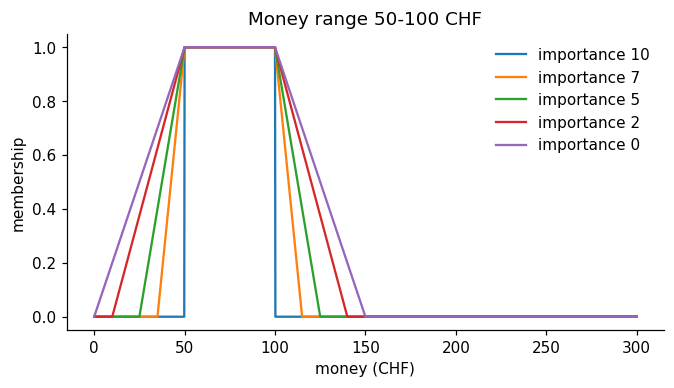

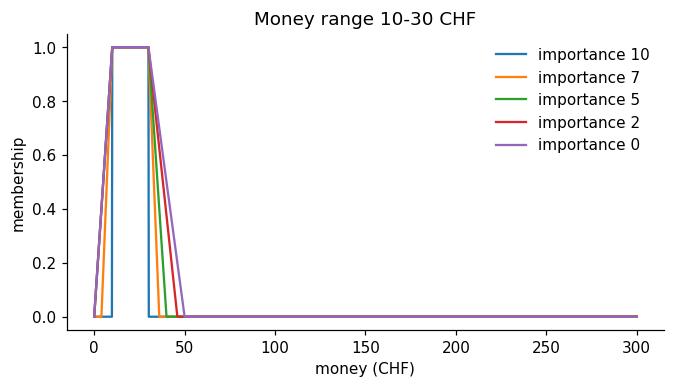

In [6]:
MONEY = np.linspace(0, 300, 1501)    # money axis in CHF

MONEY_SOFTNESS = 1.0   # how wide the slopes get at importance 0 (1.0 = as wide as the range)


def money_membership(max_money, importance, min_money=0, x=MONEY):
    """Fuzzy set for 'how much I want to spend', on the grid x (in CHF).

    max_money   upper end of the range
    min_money   lower end of the range (default 0)
    importance  0-10: 10 = crisp rectangle, 0 = very soft slopes
    """
    importance = float(np.clip(importance, 0, 10))
    softness = (10 - importance) / 10                         # 0 = crisp, ..., 1 = very soft slope
    w = softness * MONEY_SOFTNESS * (max_money - min_money)   # width of each slope

    a = max(min_money - w, 0)
    b = min_money
    c = max_money
    d = max_money + w
    return shape(a, b, c, d, x)


# Plot 1
fig, ax = plt.subplots(figsize=(7, 3.5))
for imp in [10, 7, 5, 2, 0]:
    ax.plot(MONEY, money_membership(100, imp, 50), label=f'importance {imp}')
ax.set_xlabel('money (CHF)')
ax.set_ylabel('membership')
ax.set_title('Money range 50-100 CHF')
ax.legend(frameon=False)
plt.show()

# Plot 2
fig, ax = plt.subplots(figsize=(7, 3.5))
for imp in [10, 7, 5, 2, 0]:
    ax.plot(MONEY, money_membership(30, imp, 10), label=f'importance {imp}')
ax.set_xlabel('money (CHF)')
ax.set_ylabel('membership')
ax.set_title('Money range 10-30 CHF')
ax.legend(frameon=False)
plt.show()

## Group size membership function

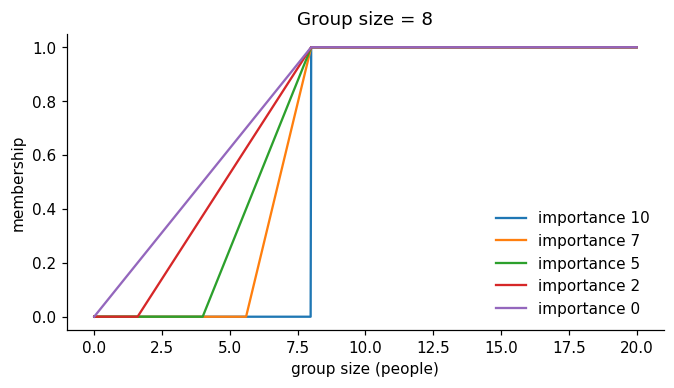

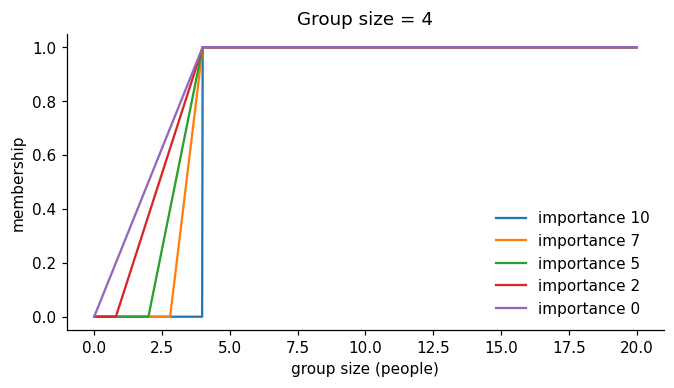

In [10]:
PEOPLE = np.linspace(0, 20, 1001)    # group size axis in people

GROUP_SOFTNESS = 1.0   # how far left the ramp starts at importance 0 (1.0 = starts at 0)


def group_membership(size, importance, x=PEOPLE):
    """Fuzzy set for 'a group of at least this size', on the grid x (in people).

    size        the group size (number of people)
    importance  0-10: 10 = crisp step (rectangle), 0 = very soft ramp
    """
    importance = float(np.clip(importance, 0, 10))
    softness = (10 - importance) / 10          # 0 = crisp, ..., 1 = very soft ramp
    w = softness * GROUP_SOFTNESS * size       # width of the rising side

    a = max(size - w, 0)    # the ramp starts here (not below 0)
    b = size                # from here on the membership is 1
    top = x.max()           # c = d = end of the axis, so it stays at 1 forever
    return shape(a, b, top, top, x)


# Plot 3
fig, ax = plt.subplots(figsize=(7, 3.5))
for imp in [10, 7, 5, 2, 0]:
    ax.plot(PEOPLE, group_membership(8, imp), label=f'importance {imp}')
ax.set_xlabel('group size (people)')
ax.set_ylabel('membership')
ax.set_title('Group size = 8')
ax.legend(frameon=False)
plt.show()

# Plot 4
fig, ax = plt.subplots(figsize=(7, 3.5))
for imp in [10, 7, 5, 2, 0]:
    ax.plot(PEOPLE, group_membership(4, imp), label=f'importance {imp}')
ax.set_xlabel('group size (people)')
ax.set_ylabel('membership')
ax.set_title('Group size = 4')
ax.legend(frameon=False)
plt.show()

## "Can-kids-come?" membership function
Note: this is not the same than the fuzzy keyword "Is it for kids?"

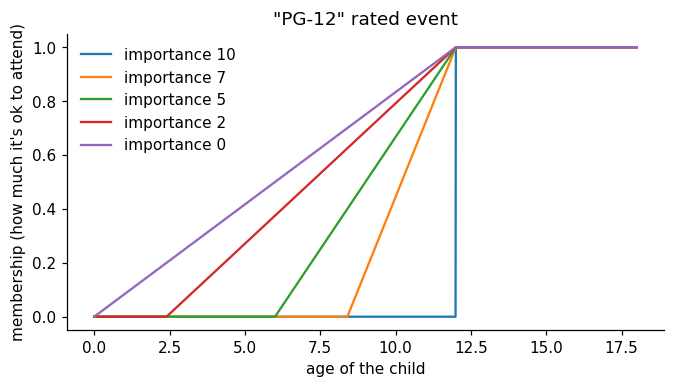

In [33]:
AGE = np.linspace(0, 18, 1801)   # age of the child who wants to attend
KIDS_OK_SOFTNESS = 1.0              # how far left the ramp starts at importance 0 (1.0 = starts at age 0)


def kids_ok_membership(min_age, importance, x=AGE):
    """Fuzzy set 'this age is OK to attend the event'.

    min_age     minimum age of the event (like a film rating: 0, 6, 12, 16, 18)
    importance  0-10: 10 = crisp step (rectangle), 0 = very soft ramp
    x           the age of the child
    """
    importance = float(np.clip(importance, 0, 10))
    softness = (10 - importance) / 10          # 0 = crisp, ..., 1 = very soft ramp
    w = softness * KIDS_OK_SOFTNESS * min_age     # width of the rising side

    a = max(min_age - w, 0)    # the ramp starts here (not below 0)
    top = x.max()              # stays at 1 until the end of the axis
    return shape(a, min_age, top, top, x)


# Plot PG-12" rated event
fig, ax = plt.subplots(figsize=(7, 3.5))
for imp in [10, 7, 5, 2, 0]:
    ax.plot(AGE, kids_ok_membership(12, imp), label=f'importance {imp}')
ax.set_title('"PG-12" rated event')
ax.set_xlabel('age of the child')
ax.set_ylabel('membership (how much it\'s ok to attend)')
ax.legend(frameon=False)
plt.show()

## Data

In [34]:
# Made-up data, it's not real data
EVENTS = [
    dict(name='Board game café',      price=12,  capacity=40,    min_age=0,  energy=2, distance_km=1,  start=19,   date='2026-11-20',
         keywords=dict(social=1.0, quiet=0.6, creative=0.3)),
    dict(name='Indie cinema',         price=15,  capacity=80,    min_age=12, energy=1, distance_km=1,  start=20,   date='2026-11-20',
         keywords=dict(quiet=1.0, creative=0.4)),
    dict(name='Jazz in a small bar',  price=25,  capacity=30,    min_age=16, energy=2, distance_km=3,  start=20.5, date='2026-11-20',
         keywords=dict(quiet=0.6, social=0.6, creative=0.3)),
    dict(name='Thermal spa evening',  price=70,  capacity=50,    min_age=16, energy=1, distance_km=12, start=18,   date='2026-11-27',
         keywords=dict(quiet=1.0)),
    dict(name='Pottery workshop',     price=50,  capacity=8,     min_age=6,  energy=2, distance_km=2,  start=18.5, date='2026-11-20',
         keywords=dict(creative=1.0, quiet=0.7, social=0.5)),
    dict(name='Comedy open mic',      price=10,  capacity=60,    min_age=16, energy=3, distance_km=4,  start=20,   date='2026-11-20',
         keywords=dict(social=0.8, creative=0.5)),
    dict(name='Karaoke night',        price=15,  capacity=25,    min_age=12, energy=4, distance_km=2,  start=21,   date='2026-11-27',
         keywords=dict(party=0.8, pop=1.0, social=1.0, dance=0.3)),
    dict(name="Friend's house party", price=0,   capacity=15,    min_age=16, energy=4, distance_km=3,  start=21,   date='2026-11-20',
         keywords=dict(party=1.0, social=1.0, dance=0.7, pop=0.6)),
    dict(name='Tasting menu dinner',  price=120, capacity=12,    min_age=12, energy=2, distance_km=5,  start=19,   date='2026-11-27',
         keywords=dict(social=0.7, quiet=0.7)),
    dict(name='Full-moon hike',       price=0,   capacity=25,    min_age=6,  energy=3, distance_km=15, start=19.5, date='2026-11-20',
         keywords=dict(outdoors=1.0, social=0.6, quiet=0.7)),
    dict(name='Lantern parade',       price=0,   capacity=500,   min_age=0,  energy=3, distance_km=1,  start=18,   date='2026-11-27',
         keywords=dict(outdoors=1.0, social=0.8, creative=0.5)),
    dict(name='Techno open-air',      price=45,  capacity=2000,  min_age=18, energy=5, distance_km=25, start=22,   date='2026-11-20',
         keywords=dict(party=1.0, techno=1.0, edm=1.0, dance=1.0, outdoors=0.8)),
    dict(name='Festival headliner',   price=150, capacity=10000, min_age=16, energy=5, distance_km=60, start=20,   date='2026-11-27',
         keywords=dict(party=0.9, pop=0.8, edm=0.5, dance=0.8, outdoors=1.0, social=0.8)),
]
events = pd.DataFrame(EVENTS)
events

,name,price,capacity,min_age,energy,distance_km,start,date,keywords
0,Board game café,12,40,0,2,1,19.0,2026-11-20,"{'social': 1.0, 'quiet': 0.6, 'creative': 0.3}"
1,Indie cinema,15,80,12,1,1,20.0,2026-11-20,"{'quiet': 1.0, 'creative': 0.4}"
2,Jazz in a small bar,25,30,16,2,3,20.5,2026-11-20,"{'quiet': 0.6, 'social': 0.6, 'creative': 0.3}"
3,Thermal spa evening,70,50,16,1,12,18.0,2026-11-27,{'quiet': 1.0}
4,Pottery workshop,50,8,6,2,2,18.5,2026-11-20,"{'creative': 1.0, 'quiet': 0.7, 'social': 0.5}"
5,Comedy open mic,10,60,16,3,4,20.0,2026-11-20,"{'social': 0.8, 'creative': 0.5}"
6,Karaoke night,15,25,12,4,2,21.0,2026-11-27,"{'party': 0.8, 'pop': 1.0, 'social': 1.0, 'dan..."
7,Friend's house party,0,15,16,4,3,21.0,2026-11-20,"{'party': 1.0, 'social': 1.0, 'dance': 0.7, 'p..."
8,Tasting menu dinner,120,12,12,2,5,19.0,2026-11-27,"{'social': 0.7, 'quiet': 0.7}"
9,Full-moon hike,0,25,6,3,15,19.5,2026-11-20,"{'outdoors': 1.0, 'social': 0.6, 'quiet': 0.7}"


## Users input

In [35]:
user = dict(
    money=dict(max=40, min=0, importance=4),
    group=dict(size=6, importance=4),
    kids_ok=dict(age=10, importance=3), # kids_ok=None if no kids come
    keywords=['social', 'quiet'] # [] if no keywords are selected
)

## Relevance score

In [ ]:
# Score of one event for each criterion
def at(x):
    return np.array([float(x)])   # a single value as a grid, so we read the curve at that point


def score_money(event, u):
    if u.get('money') is None:
        return None
    m = u['money']
    return float(money_membership(m['max'], m['importance'], m['min'], x=at(event['price']))[0])


def score_group(event, u):
    if u.get('group') is None:
        return None
    g = u['group']
    # the curve belongs to the user's group size, we read it at the event's capacity
    return float(group_membership(g['size'], g['importance'], x=at(event['capacity']))[0])


def score_kids_ok(event, u):
    if u.get('kids_ok') is None: # no kids come -> this criterion is left out
        return None
    k = u['kids_ok']
    return float(kids_ok_membership(event['min_age'], k['importance'], x=at(k['age']))[0])


# Combining the fitting of membership functions and keywords separately
def strict_and(mu):
    """Product: every score has to be good, one 0 makes the result 0."""
    return float(np.prod(np.asarray(mu, float)))


def generous_or(mu):
    """1 - product of (1 - score): high as soon as one score is high."""
    return float(1 - np.prod(1 - np.asarray(mu, float)))

# Keywords: generous OR. This is high as soon as one keyword of the event matches the users needs
def keyword_degree(event, keyword):
    # TODO For now it takes just an artificial value from the table. Replace this by the keyword 
    # membership functions once they are ready
    """How well the event matches one keyword (0-1)
    """
    return event['keywords'].get(keyword, 0.0)


def score_keywords(event, u):
    if not u.get('keywords'):
        return None
    return generous_or([keyword_degree(event, k) for k in u['keywords']])

# Strict-AND criteria. Every criterion has to be good. If one score is 0, the result is 0
SCORERS = {
    'money': score_money,
    'group size': score_group,
    'kids_ok': score_kids_ok,
    'keywords': score_keywords # already combined with OR inside
}

# Relevance of the events
def relevance(event, u):
    """Relevance of one event for the user's wishes.
    """
    scores = {name: f(event, u) for name, f in SCORERS.items()}
    scores = {k: v for k, v in scores.items() if v is not None}
    return strict_and(list(scores.values())), scores


def rank(u):
    rows = []
    for e in EVENTS:
        total, scores = relevance(e, u)
        rows.append(dict(event=e['name'], relevance=total, **scores))
    return pd.DataFrame(rows).sort_values('relevance', ascending=False).reset_index(drop=True)


rank(user).round(2)

,event,relevance,money,group size,kids_ok,keywords
0,Board game café,1.00,1.00,1.0,1.00,1.00
1,Full-moon hike,0.88,1.00,1.0,1.00,0.88
2,Lantern parade,0.80,1.00,1.0,1.00,0.80
3,Indie cinema,0.76,1.00,1.0,0.76,1.00
4,Karaoke night,0.76,1.00,1.0,0.76,1.00
5,Pottery workshop,0.50,0.58,1.0,1.00,0.85
6,Friend's house party,0.46,1.00,1.0,0.46,1.00
7,Jazz in a small bar,0.39,1.00,1.0,0.46,0.84
8,Comedy open mic,0.37,1.00,1.0,0.46,0.80
9,Thermal spa evening,0.00,0.00,1.0,0.46,1.00
